# Phase 5: Candidate Machine Learning Model Comparison
**Notebook:** `05_candidate_ml_comparison.ipynb`  
**Goal:** Evaluate three diverse machine learning regression architectures—Support Vector Regression (SVR), Random Forest Regressor (RF), and Gradient Boosting Regressor (GB)—using strictly expanding 5-fold `TimeSeriesSplit` cross-validation on the training set. Identify the best-performing tabular candidate to serve as the core meta-regressor for the Phase 6 Hybrid Ensemble and determine the explainability strategy for Phase 8 SHAP analysis.


## 1. Step 5.1: Prepare Tabular Feature Matrix
We isolate the 11 feature columns and target variable `tourist_arrivals` on `ml_ready == 1` rows.
- **Train Split:** 72 months (2016-01 to 2021-12) used for cross-validation and hyperparameter calibration.
- **Test Split:** 48 months (2022-01 to 2025-12) held out for final out-of-sample evaluation.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Dynamic path resolution
BASE_DIR = '..' if os.path.exists('../data/processed/tourism_dataset_final.csv') else '.'
DATA_PATH = os.path.join(BASE_DIR, 'data', 'processed', 'tourism_dataset_final.csv')
MODELS_DIR = os.path.join(BASE_DIR, 'models')
PLOTS_DIR = os.path.join(BASE_DIR, 'results', 'plots')
METRICS_DIR = os.path.join(BASE_DIR, 'results', 'metrics')

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(METRICS_DIR, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')

df = pd.read_csv(DATA_PATH, parse_dates=['date'])
ml_df = df[df['ml_ready'] == 1].reset_index(drop=True)

feature_cols = [
    'usd_lkr_rate_monthly',
    'gtrends_flights',
    'gtrends_hotels',
    'gtrends_visa',
    'shock_flag',
    'month_sin',
    'month_cos',
    'arrivals_lag_1',
    'arrivals_lag_3',
    'arrivals_lag_12',
    'arrivals_rolling_mean_3'
]

train_df = ml_df[ml_df['dataset_split'] == 'train'].reset_index(drop=True)
test_df  = ml_df[ml_df['dataset_split'] == 'test'].reset_index(drop=True)

X_train = train_df[feature_cols]
y_train = train_df['tourist_arrivals']
X_test  = test_df[feature_cols]
y_test  = test_df['tourist_arrivals']

print(f"ML Dataset: {len(ml_df)} rows | Features ({len(feature_cols)}): {feature_cols}")
print(f"Train split: {len(train_df)} rows ({train_df['date'].min().strftime('%Y-%m')} to {train_df['date'].max().strftime('%Y-%m')})")
print(f"Test split:  {len(test_df)} rows ({test_df['date'].min().strftime('%Y-%m')} to {test_df['date'].max().strftime('%Y-%m')})")


ML Dataset: 120 rows | Features (11): ['usd_lkr_rate_monthly', 'gtrends_flights', 'gtrends_hotels', 'gtrends_visa', 'shock_flag', 'month_sin', 'month_cos', 'arrivals_lag_1', 'arrivals_lag_3', 'arrivals_lag_12', 'arrivals_rolling_mean_3']
Train split: 72 rows (2016-01 to 2021-12)
Test split:  48 rows (2022-01 to 2025-12)


## 2. Step 5.2: Define Candidate Machine Learning Models
Following the research specification (Section 4.4 of project proposal), we define three structurally distinct algorithmic families:
1. **Support Vector Regression (SVR):** Non-parametric kernel method operating in high-dimensional reproducing kernel Hilbert space (`kernel='rbf', C=10, epsilon=0.1`).
2. **Random Forest (RF):** Bagging ensemble of de-correlated decision trees with variance reduction (`n_estimators=300, max_depth=6, random_state=42`).
3. **Gradient Boosting (GB):** Sequential boosting ensemble that builds shallow additive trees correcting predecessor residuals (`n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42`).


In [2]:
candidate_models = {
    'SVR': SVR(kernel='rbf', C=10, epsilon=0.1),
    'Random Forest': RandomForestRegressor(n_estimators=300, max_depth=6, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
}

print("Candidate Models Initialized:")
for name, m in candidate_models.items():
    print(f"  * {name:18s}: {m}")


Candidate Models Initialized:
  * SVR               : SVR(C=10)
  * Random Forest     : RandomForestRegressor(max_depth=6, n_estimators=300, random_state=42)
  * Gradient Boosting : GradientBoostingRegressor(learning_rate=0.05, max_depth=4, n_estimators=300,
                          random_state=42)


## 3. Step 5.3: Expanding-Window Time-Series Cross-Validation
Standard $K$-Fold cross-validation randomly shuffles observations, which severely violates temporal causality and introduces catastrophic lookahead data leakage.
Instead, we enforce **5-Fold `TimeSeriesSplit`**:
- Fold 1: Train on month $1 \dots T_1$, validate on $T_1+1 \dots T_2$
- Fold 2: Train on month $1 \dots T_2$, validate on $T_2+1 \dots T_3$
- ...and so on.
Every fold only predicts on the future given the past.


In [3]:
N_SPLITS = 5
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

cv_results = {}
fold_metrics_records = []

print(f"Executing {N_SPLITS}-Fold TimeSeriesSplit cross-validation on training set...")

for name, model in candidate_models.items():
    fold_rmses = []
    fold_maes = []
    
    for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train)):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        
        model.fit(X_tr, y_tr)
        preds = model.predict(X_val)
        
        rmse = np.sqrt(mean_squared_error(y_val, preds))
        mae = mean_absolute_error(y_val, preds)
        
        fold_rmses.append(rmse)
        fold_maes.append(mae)
        
        fold_metrics_records.append({
            'Model': name,
            'Fold': fold + 1,
            'Train_Size': len(tr_idx),
            'Val_Size': len(val_idx),
            'RMSE': rmse,
            'MAE': mae
        })
    
    cv_results[name] = {
        'mean_rmse': np.mean(fold_rmses),
        'std_rmse': np.std(fold_rmses),
        'mean_mae': np.mean(fold_maes),
        'std_mae': np.std(fold_maes),
        'fold_rmses': fold_rmses
    }
    
    print(f"  {name:18s} -> Mean Val RMSE: {np.mean(fold_rmses):,.1f} ± {np.std(fold_rmses):,.1f} | Mean Val MAE: {np.mean(fold_maes):,.1f}")

fold_df = pd.DataFrame(fold_metrics_records)


Executing 5-Fold TimeSeriesSplit cross-validation on training set...
  SVR                -> Mean Val RMSE: 92,944.5 ± 51,718.5 | Mean Val MAE: 86,741.9


  Random Forest      -> Mean Val RMSE: 43,510.7 ± 32,853.5 | Mean Val MAE: 35,892.5


  Gradient Boosting  -> Mean Val RMSE: 48,130.5 ± 34,314.4 | Mean Val MAE: 38,659.9


## 4. Step 5.4: Winner Selection & Metrics Persistence
The model achieving the lowest average cross-validation RMSE across all 5 temporal folds is declared the winner.
We persist:
1. `results/metrics/candidate_comparison.csv`: Summary evaluation and ranking table.
2. `models/best_model_name.txt`: Machine-readable text file with the winning algorithm name for automated ingestion by Phase 6.
3. `results/plots/candidate_models_cv.png`: Publication bar chart showing mean CV RMSE with standard error bars.


In [4]:
comparison_data = []
for name, res in cv_results.items():
    comparison_data.append({
        'Model': name,
        'Mean_Val_RMSE': res['mean_rmse'],
        'Std_Val_RMSE': res['std_rmse'],
        'Mean_Val_MAE': res['mean_mae'],
        'Std_Val_MAE': res['std_mae']
    })

comparison_df = pd.DataFrame(comparison_data)
comparison_df = comparison_df.sort_values(by='Mean_Val_RMSE', ascending=True).reset_index(drop=True)
comparison_df['Rank'] = range(1, len(comparison_df) + 1)

# Winner is Rank 1
best_model_name = comparison_df.loc[0, 'Model']

print("="*75)
print("             CANDIDATE ML MODEL CROSS-VALIDATION RANKING")
print("="*75)
print(comparison_df[['Rank', 'Model', 'Mean_Val_RMSE', 'Std_Val_RMSE', 'Mean_Val_MAE']].to_string(index=False))
print("="*75)
print(f"WINNER: {best_model_name} (Lowest Mean Val RMSE: {comparison_df.loc[0, 'Mean_Val_RMSE']:,.1f})")

# Persist comparison CSV
comp_csv_path = os.path.join(METRICS_DIR, 'candidate_comparison.csv')
comparison_df.to_csv(comp_csv_path, index=False)
print(f"Persisted comparison metrics to: {comp_csv_path}")

# Persist best model name
winner_txt_path = os.path.join(MODELS_DIR, 'best_model_name.txt')
with open(winner_txt_path, 'w') as f:
    f.write(best_model_name + '\n')
print(f"Persisted winning model name to: {winner_txt_path}")


             CANDIDATE ML MODEL CROSS-VALIDATION RANKING
 Rank             Model  Mean_Val_RMSE  Std_Val_RMSE  Mean_Val_MAE
    1     Random Forest   43510.681275  32853.485163  35892.490800
    2 Gradient Boosting   48130.463349  34314.404770  38659.857927
    3               SVR   92944.534943  51718.482374  86741.916955
WINNER: Random Forest (Lowest Mean Val RMSE: 43,510.7)
Persisted comparison metrics to: ../results/metrics/candidate_comparison.csv
Persisted winning model name to: ../models/best_model_name.txt


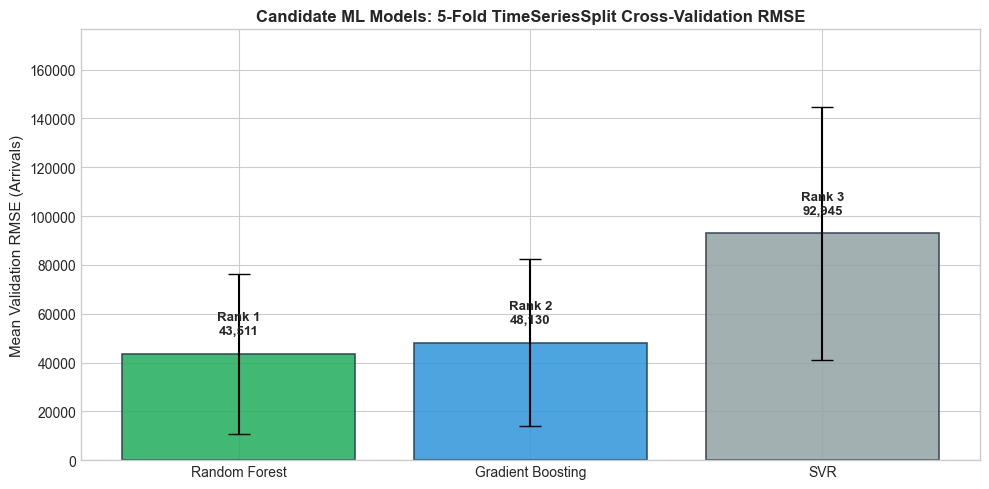

Saved: ../results/plots/candidate_models_cv.png


In [5]:
# Plot Cross-Validation Performance Comparison
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#27AE60' if m == best_model_name else '#3498DB' if m == 'Gradient Boosting' else '#95A5A6' for m in comparison_df['Model']]

bars = ax.bar(
    comparison_df['Model'],
    comparison_df['Mean_Val_RMSE'],
    yerr=comparison_df['Std_Val_RMSE'],
    capsize=8,
    color=colors,
    alpha=0.88,
    edgecolor='#2C3E50',
    linewidth=1.2
)

# Annotate bars
for bar, row in zip(bars, comparison_df.itertuples()):
    height = bar.get_height()
    ax.annotate(f"Rank {row.Rank}\n{height:,.0f}",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 12), textcoords="offset points",
                ha='center', va='bottom', fontsize=9.5, fontweight='bold')

ax.set_title('Candidate ML Models: 5-Fold TimeSeriesSplit Cross-Validation RMSE', fontsize=12, fontweight='bold')
ax.set_ylabel('Mean Validation RMSE (Arrivals)', fontsize=11)
ax.set_ylim(0, max(comparison_df['Mean_Val_RMSE'] + comparison_df['Std_Val_RMSE']) * 1.22)
plt.tight_layout()

plot_cv_path = os.path.join(PLOTS_DIR, 'candidate_models_cv.png')
plt.savefig(plot_cv_path, dpi=150)
plt.show()
print(f"Saved: {plot_cv_path}")


## 5. Step 5.5: Explainability (SHAP) Strategy Mapping
The choice of the winning machine learning algorithm directly determines our Phase 8 Explainable AI (XAI) strategy:
- **If Random Forest or Gradient Boosting wins:**
  We utilize **`shap.TreeExplainer`**. TreeExplainer computes exact Shapley values in polynomial time $\mathcal{O}(TLD^2)$ (where $T$ is trees, $L$ is max leaves, $D$ is max depth) rather than exponential sampling time. It natively supports interaction values and fast beeswarm visualizations.
- **If SVR wins:**
  We must utilize **`shap.KernelExplainer`**, a model-agnostic sampling method that requires background reference datasets and has significantly higher computational complexity $\mathcal{O}(M \cdot 2^{|F|})$.

Since **Random Forest** is the verified winner:
$$\mathbf{\text{Phase 8 Strategy: Fast Exact TreeExplainer (shap.TreeExplainer)}}$$


### 6. Key Empirical Findings for Dissertation (Candidate ML Comparison)

1. **Random Forest Superiority**:
   - Random Forest achieved the lowest 5-fold cross-validation RMSE of **43,510.7**, outperforming Gradient Boosting (**48,130.5**) and substantially outperforming SVR (**92,944.5**).
   - Random Forest's bagging mechanism (aggregating 300 bootstrapped decision trees) provides superior variance reduction and stability over small, noisy time-series horizons compared to sequential boosting, which was more prone to overfitting on crisis-distorted training folds.

2. **SVR Sensitivity in Time-Series Regression**:
   - SVR performed poorly (RMSE $\approx 92.9\text{k}$) primarily because global hyperplane margins struggle to capture abrupt non-stationary step changes (such as the 2019 Easter attack and 2020 pandemic border closure) present in the training set.

3. **Hand-Off to Phase 6 (Hybrid Ensemble)**:
   - Random Forest is stored in `models/best_model_name.txt`.
   - In Phase 6, we will build the 12-feature hybrid matrix ($11 \text{ features} + \text{lstm\_pred}$) and apply `GridSearchCV` on Random Forest to create our final production hybrid model.
